# Stimulus lag of the RF fit

The RF fits (`cottage_analysis.analysis.spheres.rf_fitting.fit_3d_rfs`, `shift_stim=2`) regress the response of imaging frame
*t* on the stimulus at the start of frame *t* − 2, a lag of **2 frames (131 ms at 15.2 Hz)**. The paper RFs are fitted on
deconvolved spikes (τ 1.1 s GCaMP6s, 0.25 s GCaMP6f, see `tau_estimation.ipynb`) with this lag (`precompute_data/rf_fit_spikes.py`).

To check the lag, the RF fit was redone at whole-frame lags (Oct 2026, NEMO), with the hyperparameter search of the pipeline
at every lag, on the 5 multidepth sessions:

- multidepth recordings (`latency_sweep.py --model snapshot`): cells with R² > 0.05 in a previous fit, lags 0–20 frames on
  dF/F, 0–10 on spikes;
- single-depth recordings (`single_depth_lag_sweep.py`): cells with a pipeline single-depth R² > 0.03, same lags.

For each cell, held-out R² at each lag is divided by its best R² over lags; curves are the median over cells.
`data/lag_sweep/lag_sweep_summary.csv` holds these summaries only (`summarise_lag_sweeps.py`).

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

COL = {"GCaMP6s": "#2a78d6", "GCaMP6f": "#eb6834"}
LS = {"multidepth": "-", "single_depth": "--"}
LAG = 2
plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 120, "savefig.dpi": 120})
t = pd.read_csv("data/lag_sweep/lag_sweep_summary.csv")

## R² against lag

Left: dF/F. Right: spikes. Top: mean of the session curves of each indicator, multidepth and single depth together.
Bottom: one curve per session (solid: multidepth, dashed: single depth). Dotted line: the lag of the fits.

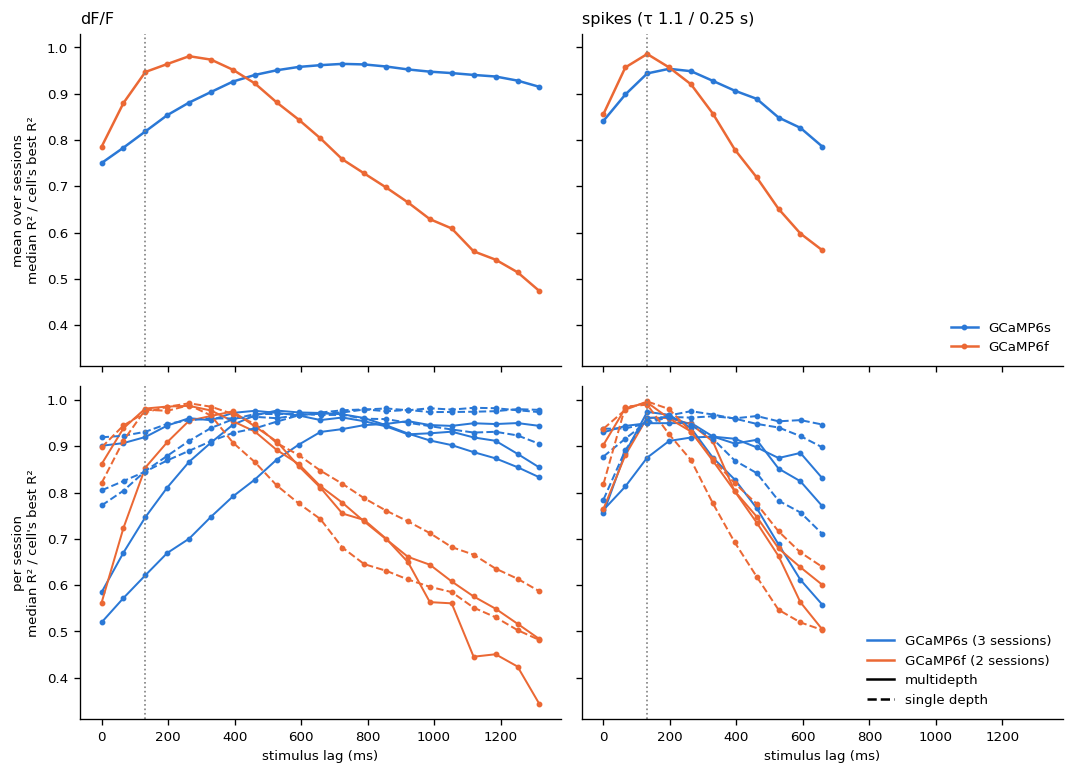

In [ ]:
from matplotlib.lines import Line2D

fig, axs = plt.subplots(2, 2, figsize=(9, 6.5), sharex=True, sharey=True)
for col, sig in enumerate(["dff", "spikes"]):
    d = t[t.signal == sig]
    for ind in COL:
        m = d[d.indicator == ind].groupby("lag_frames")[["lag_ms", "median_r2_rel_best"]].mean()
        axs[0, col].plot(m.lag_ms, m.median_r2_rel_best, marker="o", ms=2.5, lw=1.5, c=COL[ind], label=ind)
    for (rec, s), g in d.groupby(["recording", "session"]):
        axs[1, col].plot(g.lag_ms, g.median_r2_rel_best, LS[rec], marker="o", ms=2.5, lw=1.2,
                         c=COL[g.indicator.iloc[0]])
    axs[0, col].set_title("dF/F" if sig == "dff" else "spikes (τ 1.1 / 0.25 s)", loc="left")
    axs[1, col].set_xlabel("stimulus lag (ms)")
for ax in axs.flat:
    ax.axvline(t.lag_ms[t.lag_frames == LAG].iloc[0], c="0.5", ls=":", lw=1)
axs[0, 0].set_ylabel("mean over sessions\nmedian R² / cell's best R²")
axs[1, 0].set_ylabel("per session\nmedian R² / cell's best R²")
axs[0, 1].legend(frameon=False, loc="lower right")
axs[1, 1].legend(handles=[Line2D([], [], c=COL["GCaMP6s"], label="GCaMP6s (3 sessions)"),
                          Line2D([], [], c=COL["GCaMP6f"], label="GCaMP6f (2 sessions)"),
                          Line2D([], [], c="k", ls="-", label="multidepth"),
                          Line2D([], [], c="k", ls="--", label="single depth")], frameon=False, loc="lower right")
fig.tight_layout()

## Best lag and R² at the lag used

Per session: lag of the peak of the median curve, median R² / best at 2 frames, and fraction of cells whose best lag is
within 1 frame of 2 (1–3 frames).

In [ ]:
rows = []
for (rec, sig, s), g in t.groupby(["recording", "signal", "session"]):
    rows.append(dict(recording=rec, signal=sig, session=s, indicator=g.indicator.iloc[0], n_cells=g.n_cells.iloc[0],
                     peak_ms=g.lag_ms[g.median_r2_rel_best.idxmax()],
                     r2_rel_best_at_lag2=g.median_r2_rel_best[g.lag_frames == LAG].iloc[0],
                     frac_best_lag_1_3=g.frac_best_lag[g.lag_frames.between(1, 3)].sum()))
summary = pd.DataFrame(rows).sort_values(["signal", "recording", "indicator", "session"])
summary.round(2)

,recording,signal,session,indicator,n_cells,peak_ms,r2_rel_best_at_lag2,frac_best_lag_1_3
3,multidepth,dff,PZAH17.1e_S20250313,GCaMP6f,37,394.9,0.85,0.14
4,multidepth,dff,PZAH17.1e_S20250318,GCaMP6f,60,263.3,0.98,0.43
0,multidepth,dff,PZAG16.3b_S20250317,GCaMP6s,192,921.5,0.62,0.01
1,multidepth,dff,PZAG16.3c_S20250317,GCaMP6s,150,526.6,0.75,0.01
2,multidepth,dff,PZAG17.3a_S20250319,GCaMP6s,27,460.8,0.92,0.07
13,single_depth,dff,PZAH17.1e_S20250313,GCaMP6f,37,263.3,0.98,0.51
14,single_depth,dff,PZAH17.1e_S20250318,GCaMP6f,54,263.3,0.97,0.41
10,single_depth,dff,PZAG16.3b_S20250317,GCaMP6s,179,1251.0,0.85,0.00
11,single_depth,dff,PZAG16.3c_S20250317,GCaMP6s,200,592.7,0.85,0.02
12,single_depth,dff,PZAG17.3a_S20250319,GCaMP6s,49,1120.0,0.93,0.04


In [ ]:
print(summary.groupby(["signal", "recording", "indicator"])[["peak_ms", "r2_rel_best_at_lag2"]]
      .agg(["min", "max"]).round(2))

                              peak_ms         r2_rel_best_at_lag2      
                                  min     max                 min   max
signal recording    indicator                                          
dff    multidepth   GCaMP6f     263.3   394.9                0.85  0.98
                    GCaMP6s     460.8   921.5                0.62  0.92
       single_depth GCaMP6f     263.3   263.3                0.97  0.98
                    GCaMP6s     592.7  1251.0                0.85  0.93
spikes multidepth   GCaMP6f     131.6   131.6                0.96  0.99
                    GCaMP6s     131.6   329.1                0.88  0.97
       single_depth GCaMP6f     131.6   131.6                0.99  1.00
                    GCaMP6s     197.6   461.0                0.95  0.96


## Best lag of each cell, spikes

Fraction of cells by best lag, pooled over sessions of each indicator (weighted by cells).

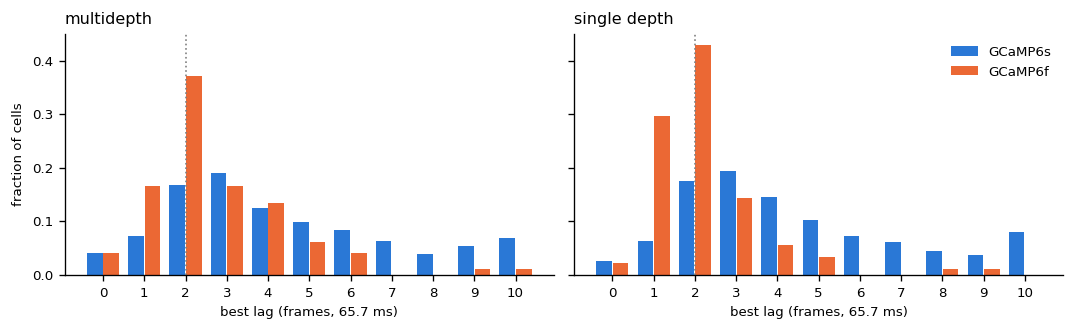

In [ ]:
sp = t[t.signal == "spikes"].assign(n_best=lambda d: d.frac_best_lag * d.n_cells)
fig, axs = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)
for ax, rec in zip(axs, ["multidepth", "single_depth"]):
    for k, ind in enumerate(COL):
        g = sp[(sp.recording == rec) & (sp.indicator == ind)].groupby("lag_frames").n_best.sum()
        ax.bar(g.index + (k - 0.5) * 0.4, g / g.sum(), width=0.38, color=COL[ind], label=ind)
    ax.axvline(LAG, c="0.5", ls=":", lw=1)
    ax.set_xticks(range(0, 11))
    ax.set_xlabel("best lag (frames, 65.7 ms)")
    ax.set_title(rec.replace("_", " "), loc="left")
axs[0].set_ylabel("fraction of cells")
axs[1].legend(frameon=False)
fig.tight_layout()

## Conclusion

- **On spikes, 2 frames is at or near the best lag** for both indicators and both recording types: the median R² at lag 2 is
  ≥ 88 % of each cell's best in every session (≥ 95 % in all but one), and the median curves peak at 130–330 ms in multidepth,
  130–460 ms in single depth, where GCaMP6s curves are broad.
- Per cell, the best lag on spikes is concentrated at 1–3 frames for GCaMP6f, and spread over 2–10 frames for GCaMP6s, whose
  curves are flat: for these cells the lag barely changes R², so the median curve rather than each cell's best is the criterion.
- **On dF/F, the best lag is longer for GCaMP6s** (0.46–1.25 s, curves flat over several hundred ms) because of the slow calcium
  decay; GCaMP6f peaks at 260–400 ms. Deconvolution removes this indicator dependence, so a single lag fits all sessions.
- Lags are whole frames: within-frame timing (scan line of each ROI, up to 66 ms) is not modelled.